# 1. Data Loading and Merging

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import entropy
from scipy.ndimage import median_filter
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

try:
    from pykalman import KalmanFilter
except ImportError:
    import subprocess
    subprocess.check_call(['pip', 'install', 'pykalman'])
    from pykalman import KalmanFilter

from sklearn.mixture import GaussianMixture

plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')


In [2]:
df_daily   = pd.read_csv('dataset_daily.csv',   parse_dates=['observation_date'])
df_weekly  = pd.read_csv('dataset_weekly.csv',  parse_dates=['observation_date'])
df_monthly = pd.read_csv('dataset_monthly.csv', parse_dates=['observation_date'])

print(f"Daily:   {df_daily.shape[0]} rows, {df_daily.shape[1]} cols, "
      f"{df_daily['observation_date'].min().date()} to {df_daily['observation_date'].max().date()}")
print(f"Weekly:  {df_weekly.shape[0]} rows, {df_weekly.shape[1]} cols")
print(f"Monthly: {df_monthly.shape[0]} rows, {df_monthly.shape[1]} cols")
print(f"\nDaily columns:   {list(df_daily.columns)}")
print(f"Weekly columns:  {list(df_weekly.columns)}")
print(f"Monthly columns: {list(df_monthly.columns)}")


Daily:   1619 rows, 10 cols, 2020-01-03 to 2026-03-13
Weekly:  324 rows, 4 cols
Monthly: 75 rows, 5 cols

Daily columns:   ['observation_date', 'Brent_Price', 'DTWEXBGS', 'EFFR', 'Gas_Price', 'Gold_Price', 'OVX_Close', 'WTI_Price', 'oil_return', 'GPRD']
Weekly columns:  ['observation_date', 'WCESTUS1', 'supply_shock', 'supply_shock_pct']
Monthly columns: ['observation_date', 'GEPUCURRENT', 'CPILFESL', 'INDPRO', 'industrial_production_growth']


In [3]:
# Merge weekly and monthly data into daily using forward-fill (merge_asof backward)
df = pd.merge_asof(
    df_daily.sort_values('observation_date'),
    df_weekly.sort_values('observation_date'),
    on='observation_date', direction='backward'
)
df = pd.merge_asof(
    df.sort_values('observation_date'),
    df_monthly.sort_values('observation_date'),
    on='observation_date', direction='backward'
)
df = df.dropna().copy().reset_index(drop=True)

print(f"Merged dataset: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Date range: {df['observation_date'].min().date()} to {df['observation_date'].max().date()}")
print(f"Null counts: {df.isnull().sum().sum()}")


Merged dataset: 1619 rows, 17 columns
Date range: 2020-01-03 to 2026-03-13
Null counts: 0


In [4]:
# Descriptive statistics
desc_cols = ['WTI_Price', 'Brent_Price', 'oil_return', 'OVX_Close', 'GPRD',
             'DTWEXBGS', 'EFFR', 'Gas_Price', 'Gold_Price']
desc = df[desc_cols].describe().T
desc['skew'] = df[desc_cols].skew()
desc['kurtosis'] = df[desc_cols].kurtosis()
desc.round(4)


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
WTI_Price,1619.0,69.8567,18.4585,-37.6300,61.3400,71.3700,80.0700,123.7000,-0.3597,1.3015
Brent_Price,1619.0,73.7619,18.5405,19.3300,64.9150,74.8100,84.3550,127.9800,-0.2533,0.4958
oil_return,1619.0,0.0007,0.0314,-0.2822,-0.0124,0.0006,0.0144,0.3196,0.0273,25.0457
OVX_Close,1619.0,43.5373,22.2398,23.7300,33.5400,37.9000,46.6500,325.1500,5.0996,36.5806
GPRD,1619.0,133.7391,65.5972,22.2619,91.1470,124.3849,163.3723,540.8274,1.8504,6.7054
DTWEXBGS,1619.0,119.5437,4.3459,110.5046,116.1322,120.1419,122.3670,130.0413,-0.0815,-0.5228
EFFR,1619.0,2.7848,2.1888,0.0400,0.0900,3.8300,4.8300,5.3300,-0.2131,-1.7225
Gas_Price,1619.0,3.5018,2.1000,1.2100,2.2200,2.8800,4.0350,30.7200,3.7652,31.0443
Gold_Price,1619.0,2283.4363,799.4747,1477.3000,1798.7000,1926.4000,2501.8000,5318.4000,1.8447,2.7871


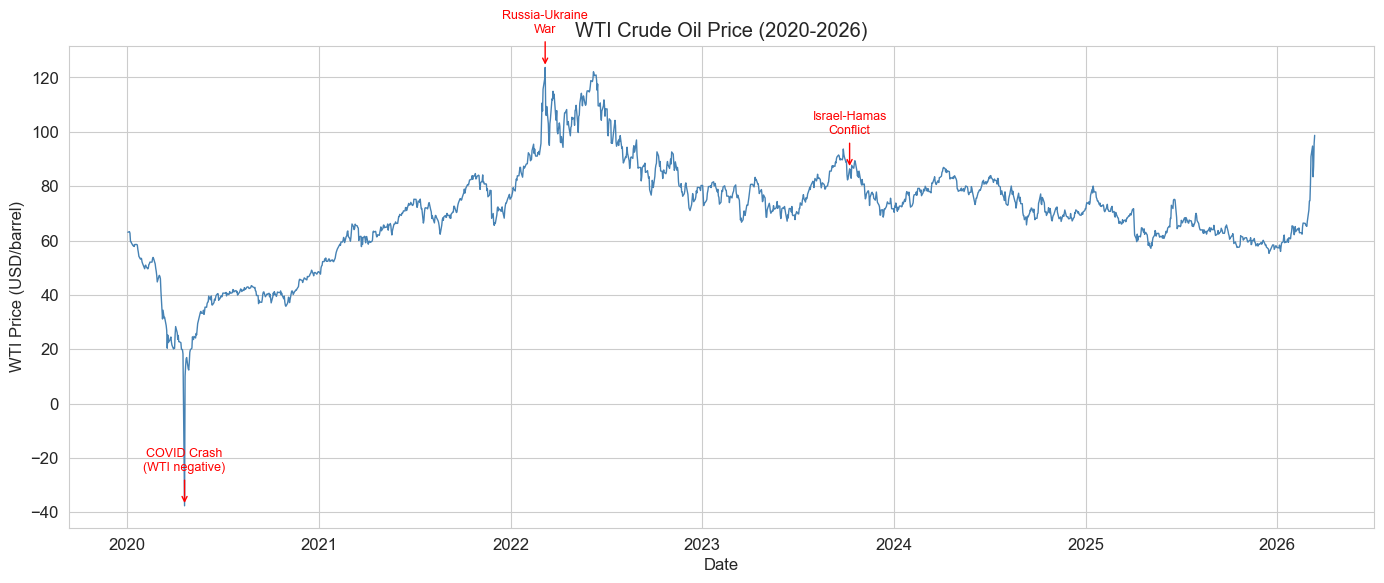

In [5]:
# WTI price time series with event annotations
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(df['observation_date'], df['WTI_Price'], color='steelblue', linewidth=1)
ax.set_xlabel('Date')
ax.set_ylabel('WTI Price (USD/barrel)')
ax.set_title('WTI Crude Oil Price (2020-2026)')

events = {
    '2020-04-20': 'COVID Crash\n(WTI negative)',
    '2022-03-08': 'Russia-Ukraine\nWar',
    '2023-10-09': 'Israel-Hamas\nConflict',
}
for date_str, label in events.items():
    date = pd.Timestamp(date_str)
    nearest_idx = (df['observation_date'] - date).abs().idxmin()
    price = df.loc[nearest_idx, 'WTI_Price']
    ax.annotate(label, xy=(date, price), xytext=(0, 25),
                textcoords='offset points', fontsize=9,
                arrowprops=dict(arrowstyle='->', color='red'),
                ha='center', color='red')
plt.tight_layout()
plt.show()


# 2. Exploratory Data Analysis — KF Observation Variables

Before regime detection, we analyse the four variables that will serve as observations
for the Kalman Filter: **Shannon Entropy** (computed in Section 3), **log(OVX)**,
**rolling\_std\_21** (21-day realised volatility), and **log(GPRD\_rolling21)**
(21-day smoothed geopolitical risk). This section examines distributions,
autocorrelation structure, and cross-correlations to inform KF model design.

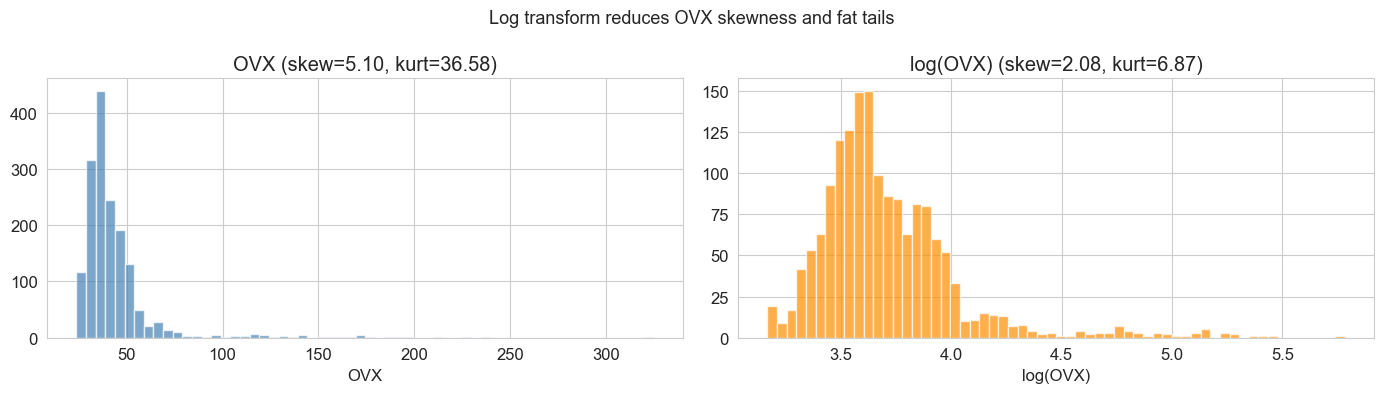

In [6]:
# Compute the four KF observation candidates
# (entropy will be added after Section 3; here we prepare the other three)
df['log_OVX'] = np.log(df['OVX_Close'])
df['rolling_std_21'] = df['oil_return'].rolling(21).std()
df['GPRD_rolling21'] = df['GPRD'].rolling(21).mean()
df['log_GPRD_r21'] = np.log(df['GPRD_rolling21'])

# Show the effect of log transform on OVX
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df['OVX_Close'].dropna(), bins=60, color='steelblue', alpha=0.7, edgecolor='white')
axes[0].set_title(f"OVX (skew={df['OVX_Close'].skew():.2f}, kurt={df['OVX_Close'].kurtosis():.2f})")
axes[0].set_xlabel('OVX')
axes[1].hist(df['log_OVX'].dropna(), bins=60, color='darkorange', alpha=0.7, edgecolor='white')
axes[1].set_title(f"log(OVX) (skew={df['log_OVX'].skew():.2f}, kurt={df['log_OVX'].kurtosis():.2f})")
axes[1].set_xlabel('log(OVX)')
fig.suptitle('Log transform reduces OVX skewness and fat tails', fontsize=13)
plt.tight_layout(); plt.show()

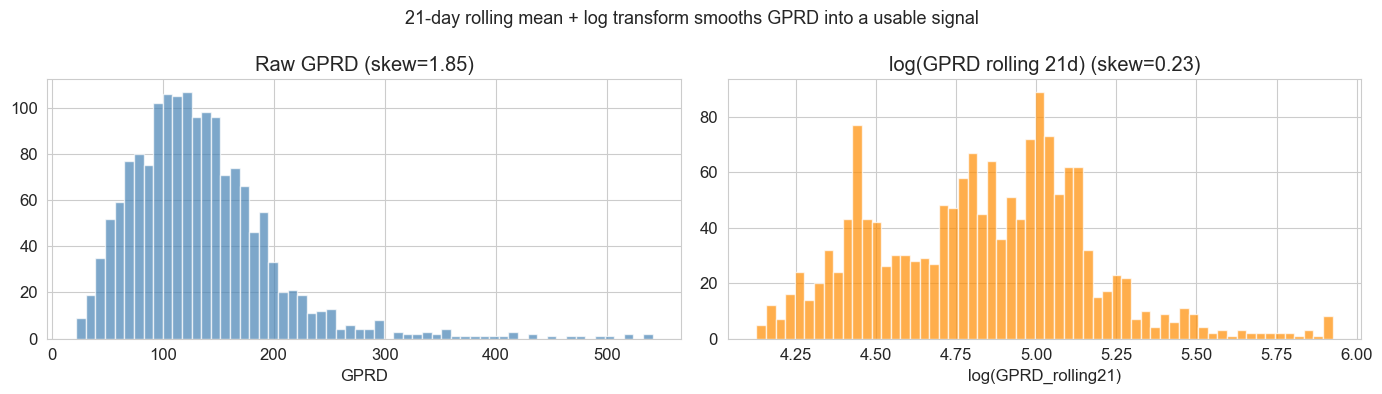

In [7]:
# Distribution of GPRD and log(GPRD_rolling21)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df['GPRD'].dropna(), bins=60, color='steelblue', alpha=0.7, edgecolor='white')
axes[0].set_title(f"Raw GPRD (skew={df['GPRD'].skew():.2f})")
axes[0].set_xlabel('GPRD')
axes[1].hist(df['log_GPRD_r21'].dropna(), bins=60, color='darkorange', alpha=0.7, edgecolor='white')
axes[1].set_title(f"log(GPRD rolling 21d) (skew={df['log_GPRD_r21'].dropna().skew():.2f})")
axes[1].set_xlabel('log(GPRD_rolling21)')
fig.suptitle('21-day rolling mean + log transform smooths GPRD into a usable signal', fontsize=13)
plt.tight_layout(); plt.show()


In [8]:
# Autocorrelation analysis — determines appropriate KF state persistence (A matrix)
obs_candidates = {
    'log_OVX': df['log_OVX'],
    'rolling_std_21': df['rolling_std_21'],
    'log_GPRD_r21': df['log_GPRD_r21'],
}
lags = [1, 5, 21, 63]

print("=== Autocorrelation Structure ===")
print(f"{'Variable':>20s}" + "".join(f"  lag-{l:<4d}" for l in lags) + "  Half-life (days)")
print("-" * 80)
for name, series in obs_candidates.items():
    s = series.dropna()
    acs = [s.autocorr(l) for l in lags]
    rho = max(acs[0], 0.001)
    half_life = -1 / np.log(rho) if rho < 1 else float('inf')
    print(f"{name:>20s}" + "".join(f"  {ac:7.4f}" for ac in acs) + f"  {half_life:8.1f}")

print("\n(Entropy autocorrelation will be added after Section 3)")
print("\nInterpretation:")
print("  - log_OVX and entropy (~0.97 lag-1) suggest a fast-decaying state (half-life ~38 days)")
print("  - rolling_std_21 and log_GPRD_r21 (~0.99+ lag-1) suggest a slow-decaying state (half-life >100 days)")
print("  - This two-group structure motivates a 2D Kalman Filter state space")

=== Autocorrelation Structure ===
            Variable  lag-1     lag-5     lag-21    lag-63    Half-life (days)
--------------------------------------------------------------------------------
             log_OVX   0.9757   0.8899   0.6567   0.1986      40.6
      rolling_std_21   0.9919   0.9385   0.5953  -0.0065     122.5
        log_GPRD_r21   0.9972   0.9686   0.7846   0.5840     360.4

(Entropy autocorrelation will be added after Section 3)

Interpretation:
  - log_OVX and entropy (~0.97 lag-1) suggest a fast-decaying state (half-life ~38 days)
  - rolling_std_21 and log_GPRD_r21 (~0.99+ lag-1) suggest a slow-decaying state (half-life >100 days)
  - This two-group structure motivates a 2D Kalman Filter state space


# 3. Shannon Entropy — Rolling Window

In [9]:
def rolling_shannon_entropy(series, window=60, n_bins=20):
    """
    Compute rolling Shannon Entropy on a return series.
    For each window, discretize returns into n_bins equal-width bins
    and compute Shannon entropy (base 2).
    """
    entropy_values = []
    for i in range(len(series)):
        if i < window - 1:
            entropy_values.append(np.nan)
            continue
        window_data = series.iloc[i - window + 1 : i + 1].values
        if np.isnan(window_data).any():
            entropy_values.append(np.nan)
            continue
        counts, _ = np.histogram(window_data, bins=n_bins)
        probs = counts / counts.sum()
        probs = probs[probs > 0]
        H = -np.sum(probs * np.log2(probs))
        entropy_values.append(H)
    return pd.Series(entropy_values, index=series.index)


In [10]:
df['rolling_entropy'] = rolling_shannon_entropy(df['oil_return'], window=60, n_bins=20)

print(f"Entropy range: {df['rolling_entropy'].min():.4f} to {df['rolling_entropy'].max():.4f}")
print(f"Entropy mean:  {df['rolling_entropy'].mean():.4f}")
print(f"NaN count:     {df['rolling_entropy'].isna().sum()}")

# Entropy autocorrelation (completing the table from Section 2)
ent = df['rolling_entropy'].dropna()
print(f"\nEntropy autocorrelation: lag1={ent.autocorr(1):.4f}, lag5={ent.autocorr(5):.4f}, "
      f"lag21={ent.autocorr(21):.4f}, lag63={ent.autocorr(63):.4f}")
print(f"Entropy half-life: {-1/np.log(ent.autocorr(1)):.1f} days")


Entropy range: 2.6108 to 4.1526
Entropy mean:  3.6429
NaN count:     59

Entropy autocorrelation: lag1=0.9748, lag5=0.8654, lag21=0.5681, lag63=0.3566
Entropy half-life: 39.1 days


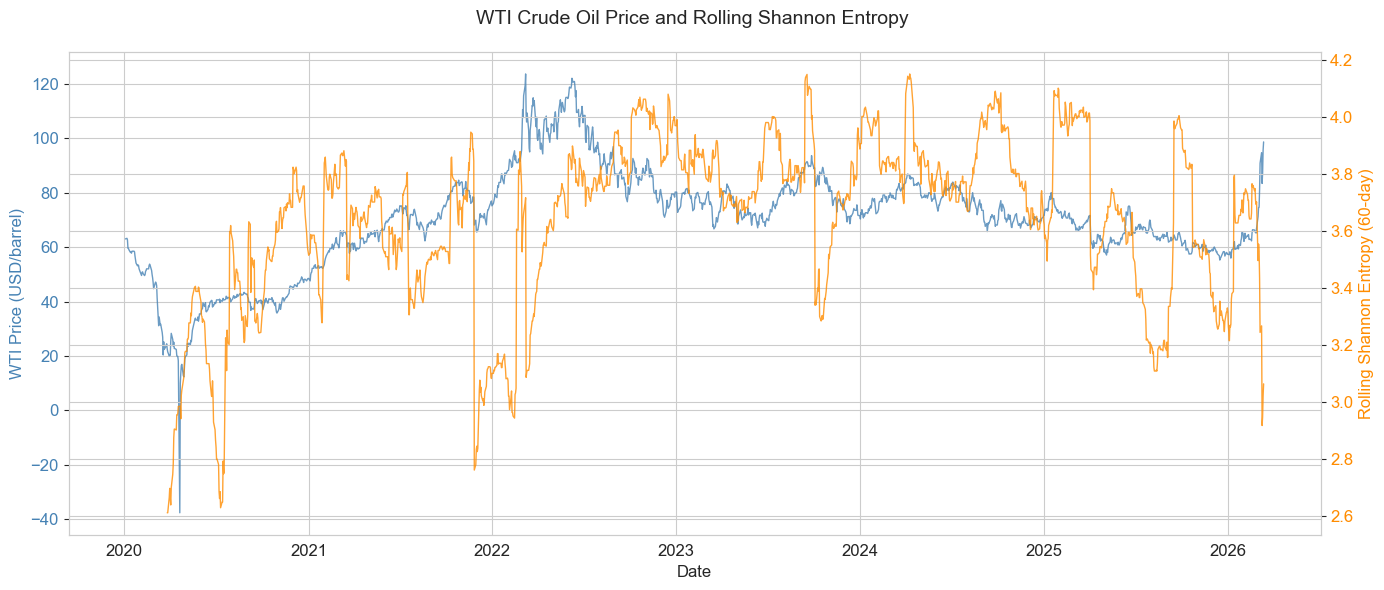

In [11]:
# WTI price + Entropy dual-axis plot
fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.set_xlabel('Date')
ax1.set_ylabel('WTI Price (USD/barrel)', color='steelblue')
ax1.plot(df['observation_date'], df['WTI_Price'], color='steelblue', linewidth=1, alpha=0.8)
ax1.tick_params(axis='y', labelcolor='steelblue')

ax2 = ax1.twinx()
ax2.set_ylabel('Rolling Shannon Entropy (60-day)', color='darkorange')
ax2.plot(df['observation_date'], df['rolling_entropy'], color='darkorange', linewidth=1, alpha=0.8)
ax2.tick_params(axis='y', labelcolor='darkorange')

fig.suptitle('WTI Crude Oil Price and Rolling Shannon Entropy', fontsize=14)
fig.tight_layout(); plt.show()


## 2b. Cross-Correlation and Z-Score Time Series

Now that entropy is computed, we analyse cross-correlations among all four
KF observations and visualise their standardised time series.

Complete cases for KF observations: 1560 rows

=== Correlation Matrix ===

Key observations:
  - log_OVX vs rolling_std_21: r=0.795 (both measure volatility)
  - entropy vs log_OVX: r=-0.433 (inverse: crises concentrate returns)
  - log_GPRD_r21 vs others: |r|<0.30 (independent geopolitical dimension)


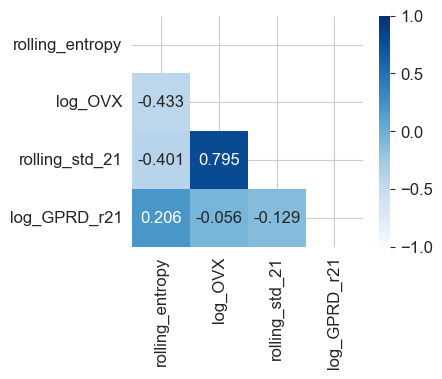

In [12]:
# Drop NaN rows (from rolling windows) for correlation analysis
obs_cols = ['rolling_entropy', 'log_OVX', 'rolling_std_21', 'log_GPRD_r21']
df_clean = df[obs_cols].copy().dropna()

print(f"Complete cases for KF observations: {len(df_clean)} rows")
print(f"\n=== Correlation Matrix ===")
corr = df_clean[obs_cols].corr()

mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(
    corr,
    mask=mask,
    cmap='Blues',
    vmin=-1, vmax=1, center=0,
    annot=True, fmt=".3f",
    square=True,
)

print(f"\nKey observations:")
print(f"  - log_OVX vs rolling_std_21: r={corr.loc['log_OVX','rolling_std_21']:.3f} (both measure volatility)")
print(f"  - entropy vs log_OVX: r={corr.loc['rolling_entropy','log_OVX']:.3f} (inverse: crises concentrate returns)")
print(f"  - log_GPRD_r21 vs others: |r|<0.30 (independent geopolitical dimension)")

In [13]:
df_clean = df[['observation_date']+obs_cols].copy().dropna()

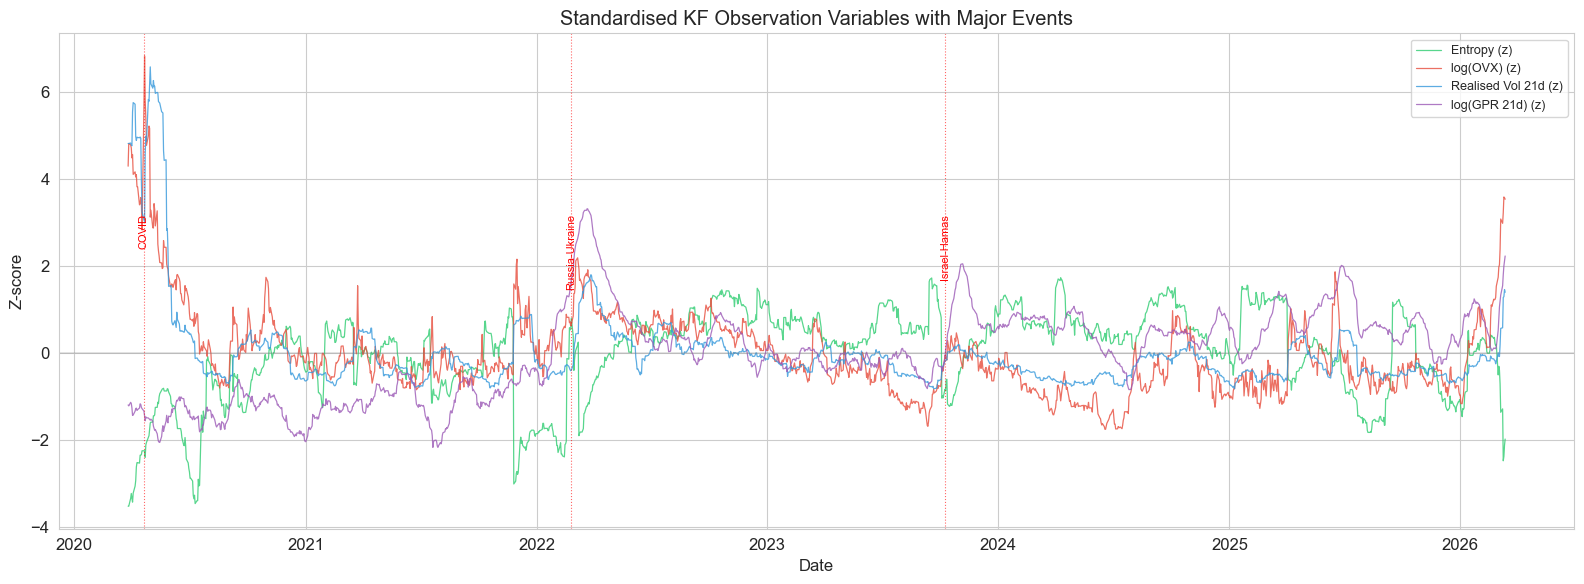

In [14]:
# Z-score time series overlay
fig, ax = plt.subplots(figsize=(16, 6))
colors = {'rolling_entropy': '#2ecc71', 'log_OVX': '#e74c3c',
          'rolling_std_21': '#3498db', 'log_GPRD_r21': '#9b59b6'}
labels = {'rolling_entropy': 'Entropy (z)', 'log_OVX': 'log(OVX) (z)',
          'rolling_std_21': 'Realised Vol 21d (z)', 'log_GPRD_r21': 'log(GPR 21d) (z)'}

for col in obs_cols:
    z = (df_clean[col] - df_clean[col].mean()) / df_clean[col].std()
    ax.plot(df_clean['observation_date'], z, color=colors[col],
            linewidth=0.9, alpha=0.8, label=labels[col])

# Event lines
for date_str, label in [('2020-04-20','COVID'), ('2022-02-24','Russia-Ukraine'), ('2023-10-09','Israel-Hamas')]:
    ax.axvline(pd.Timestamp(date_str), color='red', linestyle=':', linewidth=0.8, alpha=0.6)
    ax.text(pd.Timestamp(date_str), 3.2, label, fontsize=8, color='red',
            ha='center', rotation=90, va='top')

ax.axhline(0, color='gray', linestyle='-', linewidth=0.3)
ax.set_ylabel('Z-score'); ax.set_xlabel('Date')
ax.set_title('Standardised KF Observation Variables with Major Events')
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout(); plt.show()

# 4. Kalman Filter — State-Space Model

We estimate a linear Gaussian state-space model using the four observation variables.
Two approaches for the transition matrix **A** are compared:

- **Approach A (Free EM):** A is initialised with EDA-motivated values and estimated freely by EM.
- **Approach B (Fixed A diagonal):** A diagonal is fixed at values derived from autocorrelation analysis
  (slow state: 0.993 from rolling\_std\_21; fast state: 0.975 from entropy/log\_OVX), off-diagonals estimated by EM.

The approach with higher log-likelihood is selected.

In [15]:
# Prepare KF observations: 4 standardised variables
# Use all columns from df (not just obs_cols) so that downstream cells
# can access OVX_Close, WTI_Price, oil_return, GPRD etc.
obs_list = ['rolling_entropy', 'log_OVX', 'rolling_std_21', 'log_GPRD_r21']
valid_mask = df[obs_list].notna().all(axis=1)
df_kf = df.loc[valid_mask].copy().reset_index(drop=True)

for col in obs_list:
    mean_val = df_kf[col].mean()
    std_val  = df_kf[col].std()
    df_kf[f'{col}_z'] = (df_kf[col] - mean_val) / std_val

obs_z_cols = [f'{col}_z' for col in obs_list]
observations = df_kf[obs_z_cols].values

print(f"Observation matrix shape: {observations.shape}")
print(f"Date range: {df_kf['observation_date'].min().date()} to {df_kf['observation_date'].max().date()}")
print(f"df_kf columns: {len(df_kf.columns)}")


Observation matrix shape: (1560, 4)
Date range: 2020-03-26 to 2026-03-13
df_kf columns: 26


In [16]:
# --- Approach A: Free EM (A initialised from EDA, fully estimated) ---
A_init = np.array([[0.993, 0.0],    # slow state (rolling_std half-life ~140 days)
                   [0.0,   0.975]]) # fast state (entropy/OVX half-life ~38 days)

C_init = np.array([[0.3, 0.5],   # entropy: loads on both
                   [0.3, 0.5],   # log_OVX: loads on both
                   [0.5, 0.3],   # rolling_std: more on slow state
                   [0.5, 0.1]])  # log_GPR: mostly slow state

kf_A = KalmanFilter(
    n_dim_state=2, n_dim_obs=4,
    transition_matrices=A_init,
    observation_matrices=C_init,
    transition_covariance=np.eye(2) * 0.05,
    observation_covariance=np.eye(4) * 0.3,
    em_vars=['transition_matrices', 'observation_matrices',
             'transition_covariance', 'observation_covariance',
             'initial_state_mean', 'initial_state_covariance'],
)
kf_A = kf_A.em(observations, n_iter=20)
ll_A = kf_A.loglikelihood(observations)

diag_A = np.diag(kf_A.transition_matrices)
print("=== Approach A: Free EM ===")
print(f"  A diagonal: {diag_A.round(4)}")
print(f"  Half-lives: {(-1/np.log(np.abs(diag_A))).round(1)} days")
print(f"  Log-likelihood: {ll_A:.2f}")
print(f"  C matrix:\n{kf_A.observation_matrices.round(4)}")
print(f"  R diag: {np.diag(kf_A.observation_covariance).round(4)}")

=== Approach A: Free EM ===
  A diagonal: [0.997  0.9845]
  Half-lives: [337.1  64.1] days
  Log-likelihood: -1542.74
  C matrix:
[[ 0.034   0.1647]
 [ 0.4806  0.5877]
 [ 0.5192  0.6542]
 [ 0.4443 -0.2118]]
  R diag: [0.9561 0.459  0.3454 0.1247]


In [17]:
# --- Approach B: Fixed A diagonal, off-diagonals + other params estimated ---
A_fixed_diag = np.array([[0.993, 0.0],
                         [0.0,   0.975]])

kf_B = KalmanFilter(
    n_dim_state=2, n_dim_obs=4,
    transition_matrices=A_fixed_diag,
    observation_matrices=C_init,
    transition_covariance=np.eye(2) * 0.05,
    observation_covariance=np.eye(4) * 0.3,
    # Do NOT estimate transition_matrices
    em_vars=['observation_matrices',
             'transition_covariance', 'observation_covariance',
             'initial_state_mean', 'initial_state_covariance'],
)
kf_B = kf_B.em(observations, n_iter=20)
ll_B = kf_B.loglikelihood(observations)

print("=== Approach B: Fixed A diagonal ===")
print(f"  A diagonal: {np.diag(kf_B.transition_matrices).round(4)} (fixed)")
print(f"  Half-lives: {(-1/np.log(np.abs(np.diag(kf_B.transition_matrices)))).round(1)} days")
print(f"  Log-likelihood: {ll_B:.2f}")
print(f"  C matrix:\n{kf_B.observation_matrices.round(4)}")
print(f"  R diag: {np.diag(kf_B.observation_covariance).round(4)}")


=== Approach B: Fixed A diagonal ===
  A diagonal: [0.993 0.975] (fixed)
  Half-lives: [142.4  39.5] days
  Log-likelihood: -1555.47
  C matrix:
[[ 0.0344  0.1673]
 [ 0.479   0.5869]
 [ 0.5168  0.6518]
 [ 0.4459 -0.211 ]]
  R diag: [0.9548 0.4597 0.3486 0.1259]


In [18]:
# --- Select the better approach ---
print(f"\n=== Model Comparison ===")
print(f"  Approach A (Free EM):       LL = {ll_A:.2f}")
print(f"  Approach B (Fixed A diag):  LL = {ll_B:.2f}")
print(f"  Difference: {ll_A - ll_B:.2f}")

if ll_A >= ll_B:
    kf_selected = kf_A
    selected_label = "A (Free EM)"
    print(f"  -> Selected: Approach A (higher log-likelihood)")
else:
    kf_selected = kf_B
    selected_label = "B (Fixed A diagonal)"
    print(f"  -> Selected: Approach B (higher log-likelihood)")

# Extract states
filtered_means, filtered_covs = kf_selected.filter(observations)

diag_sel = np.diag(kf_selected.transition_matrices)
slow_idx = int(np.argmax(np.abs(diag_sel)))
fast_idx = 1 - slow_idx

slow_state = filtered_means[:, slow_idx]
fast_state = filtered_means[:, fast_idx]

df_kf['hidden_state']    = slow_state    # persistent / structural risk
df_kf['transient_state'] = fast_state    # fast-decaying / short-term

print(f"\n  Slow state (x[{slow_idx}]): A_diag={diag_sel[slow_idx]:.4f}, "
      f"half-life={-1/np.log(abs(diag_sel[slow_idx])):.1f} days")
print(f"  Fast state (x[{fast_idx}]): A_diag={diag_sel[fast_idx]:.4f}, "
      f"half-life={-1/np.log(abs(diag_sel[fast_idx])):.1f} days")



=== Model Comparison ===
  Approach A (Free EM):       LL = -1542.74
  Approach B (Fixed A diag):  LL = -1555.47
  Difference: 12.73
  -> Selected: Approach A (higher log-likelihood)



  Slow state (x[0]): A_diag=0.9970, half-life=337.1 days
  Fast state (x[1]): A_diag=0.9845, half-life=64.1 days


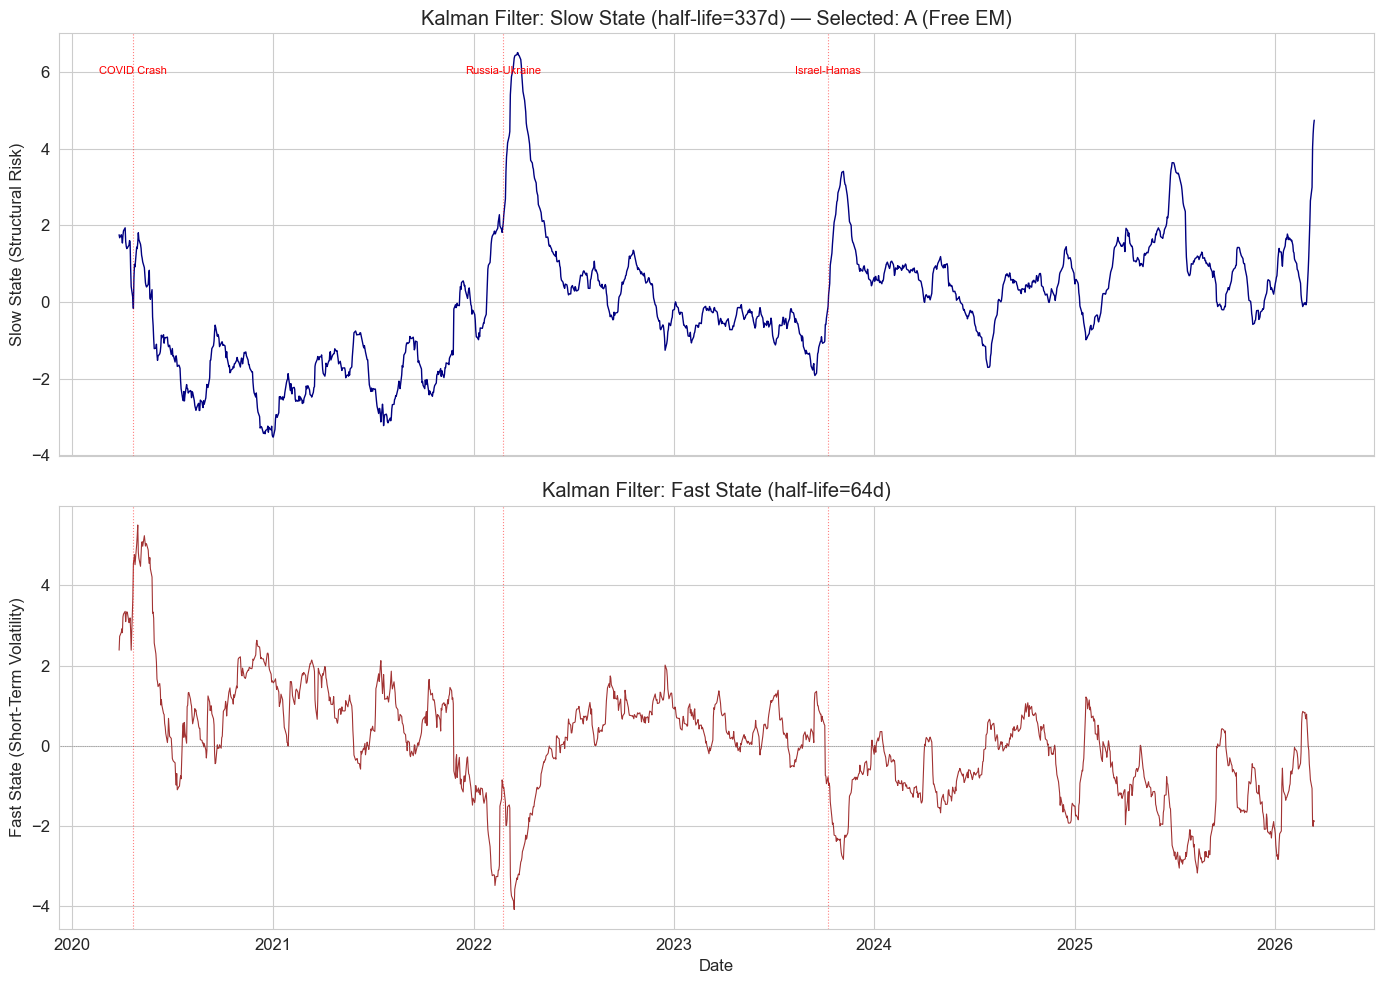

In [19]:
# 2-panel state plot
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

ax1 = axes[0]
ax1.plot(df_kf['observation_date'], slow_state, color='navy', linewidth=1)
ax1.set_ylabel('Slow State (Structural Risk)')
ax1.set_title(f'Kalman Filter: Slow State (half-life={-1/np.log(abs(diag_sel[slow_idx])):.0f}d) — Selected: {selected_label}')

ax2 = axes[1]
ax2.plot(df_kf['observation_date'], fast_state, color='darkred', linewidth=0.8, alpha=0.8)
ax2.set_ylabel('Fast State (Short-Term Volatility)')
ax2.set_xlabel('Date')
ax2.set_title(f'Kalman Filter: Fast State (half-life={-1/np.log(abs(diag_sel[fast_idx])):.0f}d)')
ax2.axhline(y=0, color='gray', linestyle=':', linewidth=0.5)

# Event annotations
for date_str, label in [('2020-04-20','COVID Crash'), ('2022-02-24','Russia-Ukraine'), ('2023-10-09','Israel-Hamas')]:
    date = pd.Timestamp(date_str)
    for ax in axes:
        ax.axvline(x=date, color='red', linestyle=':', linewidth=0.8, alpha=0.5)
    ax1.annotate(label, xy=(date, ax1.get_ylim()[1]*0.85), fontsize=8, color='red', ha='center')

plt.tight_layout(); plt.show()


# 5. Regime Classification — Gaussian Mixture Model

We compute a **composite distance** = sqrt(slow_state² + fast_state²) as GMM input.
This Euclidean distance from the origin captures both persistent risk (slow state) and
sudden shocks (fast state) regardless of sign direction — critical because COVID (fast=+5.5)
and Russia-Ukraine (fast=-1.2) are in opposite directions in the 2D state space.

Both 2-component and 3-component GMMs are fitted; BIC selects the optimal number.
A **causal** rolling majority vote (lookback only) is then applied for smoothing.

In [20]:
# Compute composite distance: Euclidean distance from origin in 2D state space
# This captures both slow (persistent) and fast (transient) risk regardless of sign direction
# COVID (fast=+5.5) and Russia-Ukraine (fast=-1.21) both produce high composite values
composite = np.sqrt(slow_state**2 + fast_state**2)
state_data = composite.reshape(-1, 1)

gmm2 = GaussianMixture(n_components=2, random_state=42, covariance_type='full')
gmm3 = GaussianMixture(n_components=3, random_state=42, covariance_type='full')
gmm2.fit(state_data)
gmm3.fit(state_data)

print("=== GMM Model Selection (on composite distance) ===")
print(f"  2-component: BIC={gmm2.bic(state_data):.2f}, AIC={gmm2.aic(state_data):.2f}")
print(f"  3-component: BIC={gmm3.bic(state_data):.2f}, AIC={gmm3.aic(state_data):.2f}")
best = '2-component' if gmm2.bic(state_data) < gmm3.bic(state_data) else '3-component'
print(f"  -> BIC selects: {best}")

for n, gmm in [(2, gmm2), (3, gmm3)]:
    means = gmm.means_.flatten()
    order = np.argsort(means)
    print(f"\n  {n}-component GMM:")
    for i, idx in enumerate(order):
        print(f"    Cluster {i}: mean={means[idx]:.3f}, weight={gmm.weights_[idx]:.3f}")

=== GMM Model Selection (on composite distance) ===
  2-component: BIC=4678.47, AIC=4651.71
  3-component: BIC=4584.37, AIC=4541.55
  -> BIC selects: 3-component

  2-component GMM:
    Cluster 0: mean=1.217, weight=0.696
    Cluster 1: mean=3.059, weight=0.304

  3-component GMM:
    Cluster 0: mean=0.964, weight=0.548
    Cluster 1: mean=2.299, weight=0.328
    Cluster 2: mean=3.992, weight=0.124


In [21]:
state_data

array([[2.96170384],
       [3.2046432 ],
       [3.33136471],
       ...,
       [4.83076712],
       [4.98282756],
       [5.10567988]], shape=(1560, 1))

In [22]:
# Select the better GMM based on BIC
if gmm2.bic(state_data) < gmm3.bic(state_data):
    gmm_selected = gmm2
    n_regimes = 2
    print("Using 2-component GMM (lower BIC)")
else:
    gmm_selected = gmm3
    n_regimes = 3
    print("Using 3-component GMM (lower BIC)")

# Assign raw regime labels (ordered by composite distance mean: lowest = Calm)
raw_labels = gmm_selected.predict(state_data)
means = gmm_selected.means_.flatten()
order = np.argsort(means)
label_map = {order[i]: i for i in range(n_regimes)}
raw_regime = np.array([label_map[l] for l in raw_labels])

# --- Soft probabilities (posterior responsibilities) ---
raw_proba = gmm_selected.predict_proba(state_data)  # shape (T, n_regimes)
# Reorder columns to match distance-ordering
proba_reordered = raw_proba[:, order]

# Fix label semantics: ensure higher regime number = higher OVX
mean_ovx_by_regime = {}
for r in range(n_regimes):
    mask = raw_regime == r
    if mask.any():
        mean_ovx_by_regime[r] = df_kf.loc[df_kf.index[mask], 'OVX_Close'].mean()

regime_order_by_ovx = sorted(mean_ovx_by_regime, key=mean_ovx_by_regime.get)
semantic_map = {regime_order_by_ovx[i]: i for i in range(n_regimes)}
raw_regime_semantic = np.array([semantic_map[r] for r in raw_regime])

# Apply same semantic remapping to probability columns
proba_semantic = np.zeros_like(proba_reordered)
for old_r, new_r in semantic_map.items():
    proba_semantic[:, new_r] = proba_reordered[:, old_r]

print(f"Mean OVX by GMM cluster (before semantic fix): {mean_ovx_by_regime}")
print(f"Semantic remapping: {semantic_map}")

# --- Causal smoothing: rolling majority vote (lookback only) ---
def causal_majority_vote(regimes, window=21):
    """Rolling mode using only past data (causal, no look-ahead)."""
    result = np.zeros_like(regimes)
    for t in range(len(regimes)):
        start = max(0, t - window + 1)
        window_data = regimes[start:t+1]
        values, counts = np.unique(window_data, return_counts=True)
        result[t] = values[np.argmax(counts)]
    return result

smoothed_regime = causal_majority_vote(raw_regime_semantic, window=21)
df_kf['regime_label'] = smoothed_regime.astype(int)

# Store soft probabilities in df_kf
for k in range(n_regimes):
    df_kf[f'regime_prob_{k}'] = proba_semantic[:, k]

print(f"\nRegime distribution (after causal smoothing):")
print(pd.Series(smoothed_regime).value_counts().sort_index())
print(f"\nRaw switches:     {(np.diff(raw_regime_semantic) != 0).sum()}")
print(f"Smoothed switches: {(np.diff(smoothed_regime) != 0).sum()}")

# Soft probability statistics
print(f"\n=== Soft Probability Statistics ===")
for k in range(n_regimes):
    col = f'regime_prob_{k}'
    vals = df_kf[col]
    print(f"  {col}: mean={vals.mean():.4f}, std={vals.std():.4f}, min={vals.min():.4f}, max={vals.max():.4f}")

# Diagnostic: check key crisis events
print("\n=== Crisis Event Coverage ===")
events = [("COVID", "2020-03-01", "2020-08-31"),
          ("Russia-Ukraine", "2022-02-01", "2022-06-30"),
          ("Israel-Hamas", "2023-10-01", "2024-01-31")]
for name, start, end in events:
    mask = (df_kf['observation_date'] >= start) & (df_kf['observation_date'] <= end)
    if mask.any():
        regime_counts = df_kf.loc[mask, 'regime_label'].value_counts().sort_index()
        total = mask.sum()
        print(f"  {name} ({start} to {end}): n={total}")
        for r, c in regime_counts.items():
            print(f"    Regime {r}: {c} days ({100*c/total:.1f}%)")
        # Mean soft probabilities during crisis
        for k in range(n_regimes):
            mean_p = df_kf.loc[mask, f'regime_prob_{k}'].mean()
            print(f"    Mean P(regime={k}): {mean_p:.4f}")


Using 3-component GMM (lower BIC)
Mean OVX by GMM cluster (before semantic fix): {0: np.float64(38.978989898989894), 1: np.float64(42.33504798464492), 2: np.float64(68.4229054054054)}
Semantic remapping: {0: 0, 1: 1, 2: 2}

Regime distribution (after causal smoothing):
0    912
1    496
2    152
Name: count, dtype: int64

Raw switches:     79
Smoothed switches: 32

=== Soft Probability Statistics ===
  regime_prob_0: mean=0.5442, std=0.4267, min=0.0000, max=0.9844
  regime_prob_1: mean=0.3303, std=0.3492, min=0.0000, max=0.9081
  regime_prob_2: mean=0.1255, std=0.2543, min=0.0049, max=1.0000

=== Crisis Event Coverage ===
  COVID (2020-03-01 to 2020-08-31): n=113
    Regime 0: 21 days (18.6%)
    Regime 1: 59 days (52.2%)
    Regime 2: 33 days (29.2%)
    Mean P(regime=0): 0.1654
    Mean P(regime=1): 0.4883
    Mean P(regime=2): 0.3464
  Russia-Ukraine (2022-02-01 to 2022-06-30): n=108
    Regime 0: 32 days (29.6%)
    Regime 1: 16 days (14.8%)
    Regime 2: 60 days (55.6%)
    Mean P

# 6. Regime Analysis and Validation

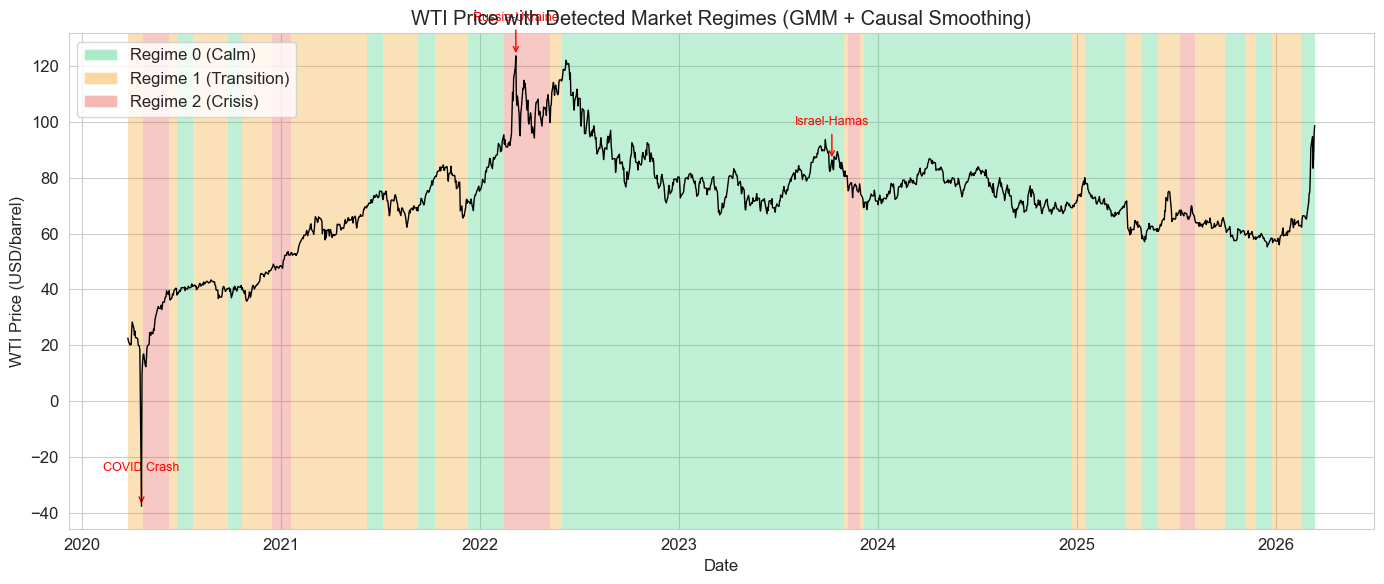

In [23]:
# Regime-colored price chart
if n_regimes == 3:
    regime_colors = {0: '#2ecc71', 1: '#f39c12', 2: '#e74c3c'}
    regime_labels_map = {0: 'Regime 0 (Calm)', 1: 'Regime 1 (Transition)', 2: 'Regime 2 (Crisis)'}
else:
    regime_colors = {0: '#2ecc71', 1: '#e74c3c'}
    regime_labels_map = {0: 'Regime 0 (Calm)', 1: 'Regime 1 (Crisis)'}

fig, ax = plt.subplots(figsize=(14, 6))
for idx in range(len(df_kf) - 1):
    ax.axvspan(df_kf.loc[idx, 'observation_date'], df_kf.loc[idx + 1, 'observation_date'],
               alpha=0.3, color=regime_colors[df_kf.loc[idx, 'regime_label']], linewidth=0)

ax.plot(df_kf['observation_date'], df_kf['WTI_Price'], color='black', linewidth=1, zorder=5)

from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=regime_colors[r], alpha=0.4, label=regime_labels_map[r])
                  for r in sorted(regime_colors.keys())]
ax.legend(handles=legend_handles, loc='upper left')
ax.set_xlabel('Date'); ax.set_ylabel('WTI Price (USD/barrel)')
ax.set_title('WTI Price with Detected Market Regimes (GMM + Causal Smoothing)')

# Event annotations
for date_str, label in [('2020-04-20','COVID Crash'), ('2022-03-08','Russia-Ukraine'), ('2023-10-09','Israel-Hamas')]:
    date = pd.Timestamp(date_str)
    nearest_idx = (df_kf['observation_date'] - date).abs().idxmin()
    price = df_kf.loc[nearest_idx, 'WTI_Price']
    ax.annotate(label, xy=(date, price), xytext=(0, 25),
                textcoords='offset points', fontsize=9,
                arrowprops=dict(arrowstyle='->', color='red'), ha='center', color='red')
plt.tight_layout(); plt.show()


In [24]:
# Regime statistics table
regime_stats = df_kf.groupby('regime_label').agg(
    count=('WTI_Price', 'size'),
    mean_return=('oil_return', 'mean'),
    std_return=('oil_return', 'std'),
    mean_OVX=('OVX_Close', 'mean'),
    std_OVX=('OVX_Close', 'std'),
    mean_entropy=('rolling_entropy', 'mean'),
    std_entropy=('rolling_entropy', 'std'),
    mean_WTI=('WTI_Price', 'mean'),
    std_WTI=('WTI_Price', 'std'),
    mean_GPRD=('GPRD', 'mean'),
).round(4)

def avg_consecutive_duration(series, regime):
    is_regime = (series == regime).astype(int)
    blocks = (is_regime.diff().fillna(0) != 0).cumsum()
    regime_blocks = blocks[is_regime == 1]
    if len(regime_blocks) == 0:
        return 0
    return regime_blocks.value_counts().mean()

for r in range(n_regimes):
    regime_stats.loc[r, 'avg_duration_days'] = avg_consecutive_duration(df_kf['regime_label'], r)

regime_stats.index = [regime_labels_map[r] for r in range(n_regimes)]
display(regime_stats)


,count,mean_return,std_return,mean_OVX,std_OVX,mean_entropy,std_entropy,mean_WTI,std_WTI,mean_GPRD,avg_duration_days
Regime 0 (Calm),912,0.0005,0.0216,38.7692,10.3804,3.7387,0.2808,75.9911,12.9397,140.0956,76.0
Regime 1 (Transition),496,0.0006,0.0316,45.4297,26.8042,3.5261,0.2649,60.8914,17.2234,113.8593,31.0
Regime 2 (Crisis),152,0.0082,0.0509,59.3603,31.0177,3.4489,0.2127,70.9812,30.4469,170.0693,30.4


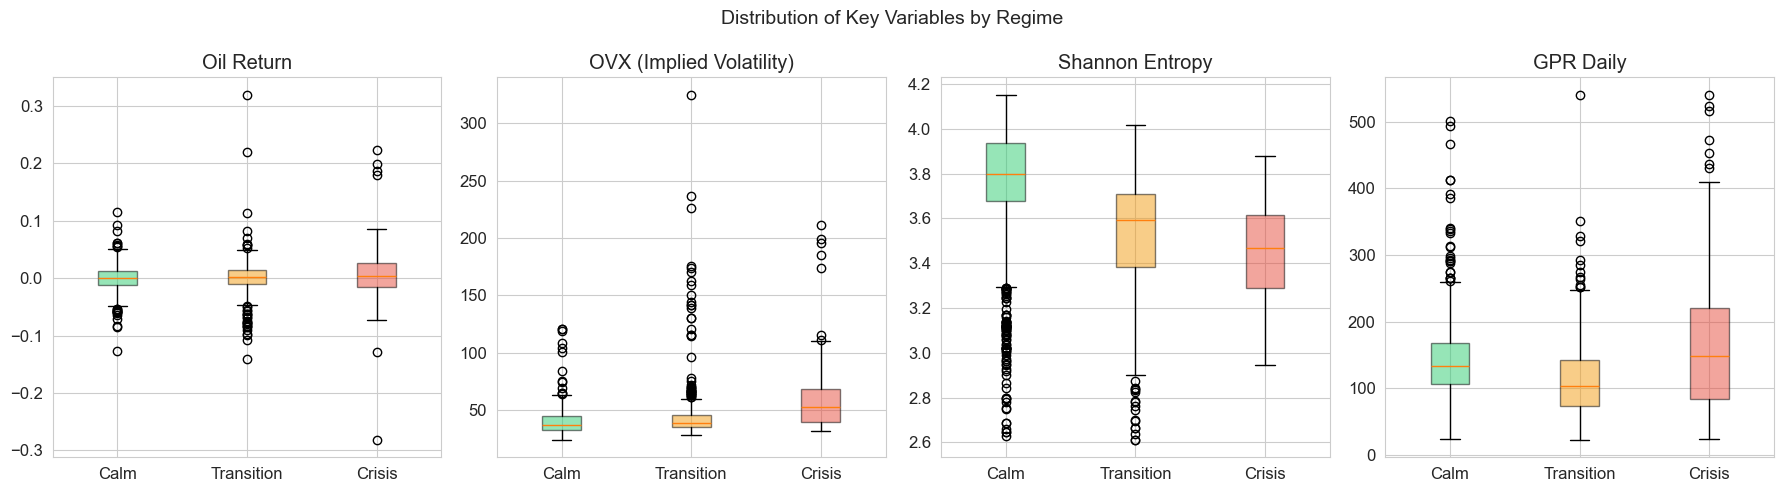

In [25]:
# Box plots by regime
plot_vars = [('oil_return', 'Oil Return'), ('OVX_Close', 'OVX (Implied Volatility)'),
             ('rolling_entropy', 'Shannon Entropy'), ('GPRD', 'GPR Daily')]
fig, axes = plt.subplots(1, len(plot_vars), figsize=(4*len(plot_vars)+2, 5))

colors_list = [regime_colors[r] for r in sorted(regime_colors.keys())]
for ax_i, (col, title) in enumerate(plot_vars):
    data_to_plot = [df_kf.loc[df_kf['regime_label'] == r, col].dropna() for r in sorted(regime_colors.keys())]
    bp = axes[ax_i].boxplot(data_to_plot, labels=[regime_labels_map[r].split('(')[1].rstrip(')') for r in sorted(regime_colors.keys())],
                            patch_artist=True)
    for patch, color in zip(bp['boxes'], colors_list):
        patch.set_facecolor(color); patch.set_alpha(0.5)
    axes[ax_i].set_title(title)

fig.suptitle('Distribution of Key Variables by Regime', fontsize=14)
plt.tight_layout(); plt.show()


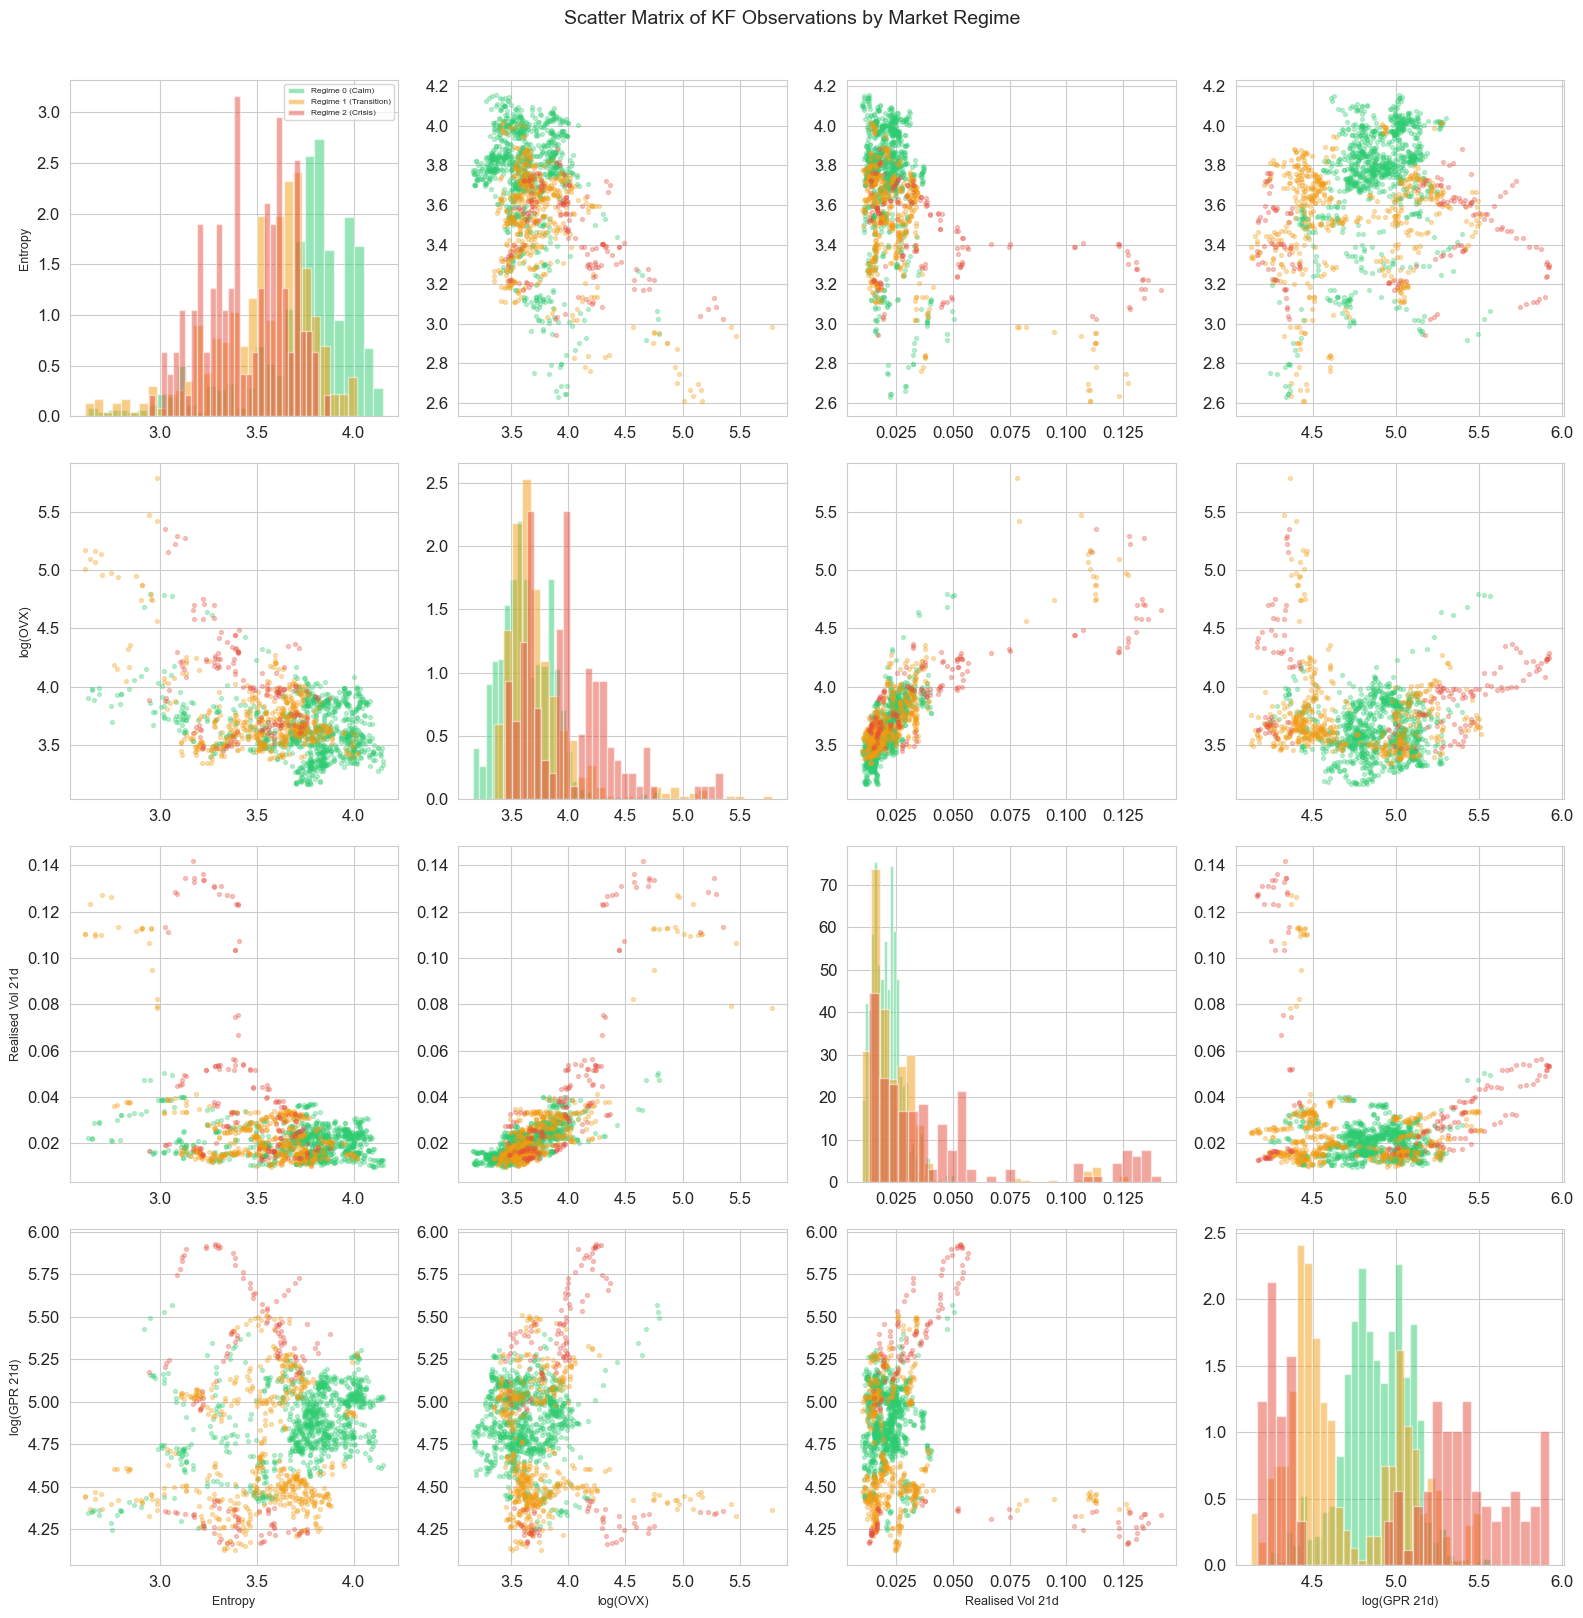

In [26]:
# Scatter matrix colored by regime
scatter_vars = ['rolling_entropy', 'log_OVX', 'rolling_std_21', 'log_GPRD_r21']
scatter_labels = ['Entropy', 'log(OVX)', 'Realised Vol 21d', 'log(GPR 21d)']

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for i in range(4):
    for j in range(4):
        ax = axes[i][j]
        if i == j:
            for r in sorted(regime_colors.keys()):
                mask = df_kf['regime_label'] == r
                ax.hist(df_kf.loc[mask, scatter_vars[i]], bins=30, alpha=0.5,
                        color=regime_colors[r], label=regime_labels_map[r], density=True)
            if i == 0:
                ax.legend(fontsize=6)
        else:
            for r in sorted(regime_colors.keys()):
                mask = df_kf['regime_label'] == r
                ax.scatter(df_kf.loc[mask, scatter_vars[j]], df_kf.loc[mask, scatter_vars[i]],
                          alpha=0.3, s=8, color=regime_colors[r])
        if i == 3:
            ax.set_xlabel(scatter_labels[j], fontsize=9)
        if j == 0:
            ax.set_ylabel(scatter_labels[i], fontsize=9)

fig.suptitle('Scatter Matrix of KF Observations by Market Regime', fontsize=14, y=1.01)
plt.tight_layout(); plt.show()

# 7. Data Export

In [27]:
df_export = df_kf.copy()
df_export['WTI_Price_next'] = df_export['WTI_Price'].shift(-1)
df_export = df_export.dropna(subset=['WTI_Price_next']).copy()

export_cols = [
    'observation_date',
    'Brent_Price', 'DTWEXBGS', 'EFFR', 'Gas_Price', 'Gold_Price',
    'OVX_Close', 'WTI_Price', 'oil_return', 'GPRD',
    'WCESTUS1', 'supply_shock', 'supply_shock_pct',
    'GEPUCURRENT', 'CPILFESL',
    'INDPRO', 'industrial_production_growth',
    'rolling_entropy', 'hidden_state', 'transient_state', 'regime_label',
    'regime_prob_0', 'regime_prob_1', 'regime_prob_2',
    'WTI_Price_next'
]

# Only include columns that exist
export_cols = [c for c in export_cols if c in df_export.columns]
df_export = df_export[export_cols]
df_export.to_csv('dataset_with_regime.csv', index=False)

print(f"Exported {df_export.shape[0]} rows, {df_export.shape[1]} columns")
print(f"Date range: {df_export['observation_date'].min()} to {df_export['observation_date'].max()}")
print(f"\nRegime distribution:")
print(df_export['regime_label'].value_counts().sort_index())
print(f"\nSoft probability columns: regime_prob_0, regime_prob_1, regime_prob_2")
print(f"Columns: {list(df_export.columns)}")


Exported 1559 rows, 25 columns
Date range: 2020-03-26 00:00:00 to 2026-03-12 00:00:00

Regime distribution:
regime_label
0    911
1    496
2    152
Name: count, dtype: int64

Soft probability columns: regime_prob_0, regime_prob_1, regime_prob_2
Columns: ['observation_date', 'Brent_Price', 'DTWEXBGS', 'EFFR', 'Gas_Price', 'Gold_Price', 'OVX_Close', 'WTI_Price', 'oil_return', 'GPRD', 'WCESTUS1', 'supply_shock', 'supply_shock_pct', 'GEPUCURRENT', 'CPILFESL', 'INDPRO', 'industrial_production_growth', 'rolling_entropy', 'hidden_state', 'transient_state', 'regime_label', 'regime_prob_0', 'regime_prob_1', 'regime_prob_2', 'WTI_Price_next']
